In [5]:
from pathlib import Path
import numpy as np

PROJECT_ROOT = Path.cwd().parent

RAW_DIR = PROJECT_ROOT / "datasets" / "raw"
NORMALIZED_DIR = PROJECT_ROOT / "datasets" / "normalized"
RESULTS_DIR = PROJECT_ROOT / "results"

NORMALIZED_DIR.mkdir(parents=True, exist_ok=True)

classes = ["normal", "irf", "orf"]

split = np.load(RESULTS_DIR / "fsl_split.npz")

train_idx = split["train_idx"]
val_idx = split["val_idx"]
test_idx = split["test_idx"]
y = split["y"]

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

Train: 210
Validation: 45
Test: 45


In [6]:
X_list = []

for class_name in classes:

    X_class = np.loadtxt(
        RAW_DIR / f"{class_name}.csv",
        delimiter=","
    )

    X_list.append(X_class)

X = np.concatenate(X_list, axis=0).astype(np.float32)

print("Raw dataset:", X.shape)

Raw dataset: (300, 100000)


In [7]:
X_list = []

for class_name in classes:

    X_class = np.loadtxt(
        RAW_DIR / f"{class_name}.csv",
        delimiter=","
    )

    X_list.append(X_class)

X = np.concatenate(X_list, axis=0).astype(np.float32)

print("Raw dataset:", X.shape)

Raw dataset: (300, 100000)


In [8]:
row_min = X.min(axis=1, keepdims=True)
row_max = X.max(axis=1, keepdims=True)

denominator = row_max - row_min
denominator[denominator == 0] = 1

X_norm = (X - row_min) / denominator

start = 0
for class_name, class_count in zip(classes, [len(np.loadtxt(RAW_DIR / f"{name}.csv", delimiter=",") ) for name in classes]):
    end = start + class_count
    np.savetxt(
        NORMALIZED_DIR / f"{class_name}.csv",
        X_norm[start:end],
        delimiter=",")
    start = end

print("Normalized dataset:", X_norm.shape)
print("Normalized files saved to:", NORMALIZED_DIR)

Normalized dataset: (300, 100000)
Normalized files saved to: c:\Users\asus\OneDrive\Desktop\siamese-network\datasets\normalized


In [9]:
row_mins = X_norm.min(axis=1)
row_maxs = X_norm.max(axis=1)

print("Smallest row minimum:", row_mins.min())
print("Largest row minimum:", row_mins.max())

print("Smallest row maximum:", row_maxs.min())
print("Largest row maximum:", row_maxs.max())

print(
    "Rows with min != 0:",
    np.sum(~np.isclose(row_mins, 0.0))
)

print(
    "Rows with max != 1:",
    np.sum(~np.isclose(row_maxs, 1.0))
)

Smallest row minimum: 0.0
Largest row minimum: 0.0
Smallest row maximum: 1.0
Largest row maximum: 1.0
Rows with min != 0: 0
Rows with max != 1: 0


In [10]:
for label, class_name in enumerate(classes):

    class_indices = np.where(y == label)[0]

    X_class_norm = X_norm[class_indices]

    output_file = NORMALIZED_DIR / f"{class_name}.csv"

    np.savetxt(
        output_file,
        X_class_norm,
        delimiter=","
    )

    print(
        f"{class_name.upper()}: "
        f"{X_class_norm.shape} -> {output_file}"
    )

NORMAL: (100, 100000) -> c:\Users\asus\OneDrive\Desktop\siamese-network\datasets\normalized\normal.csv
IRF: (100, 100000) -> c:\Users\asus\OneDrive\Desktop\siamese-network\datasets\normalized\irf.csv
ORF: (100, 100000) -> c:\Users\asus\OneDrive\Desktop\siamese-network\datasets\normalized\orf.csv


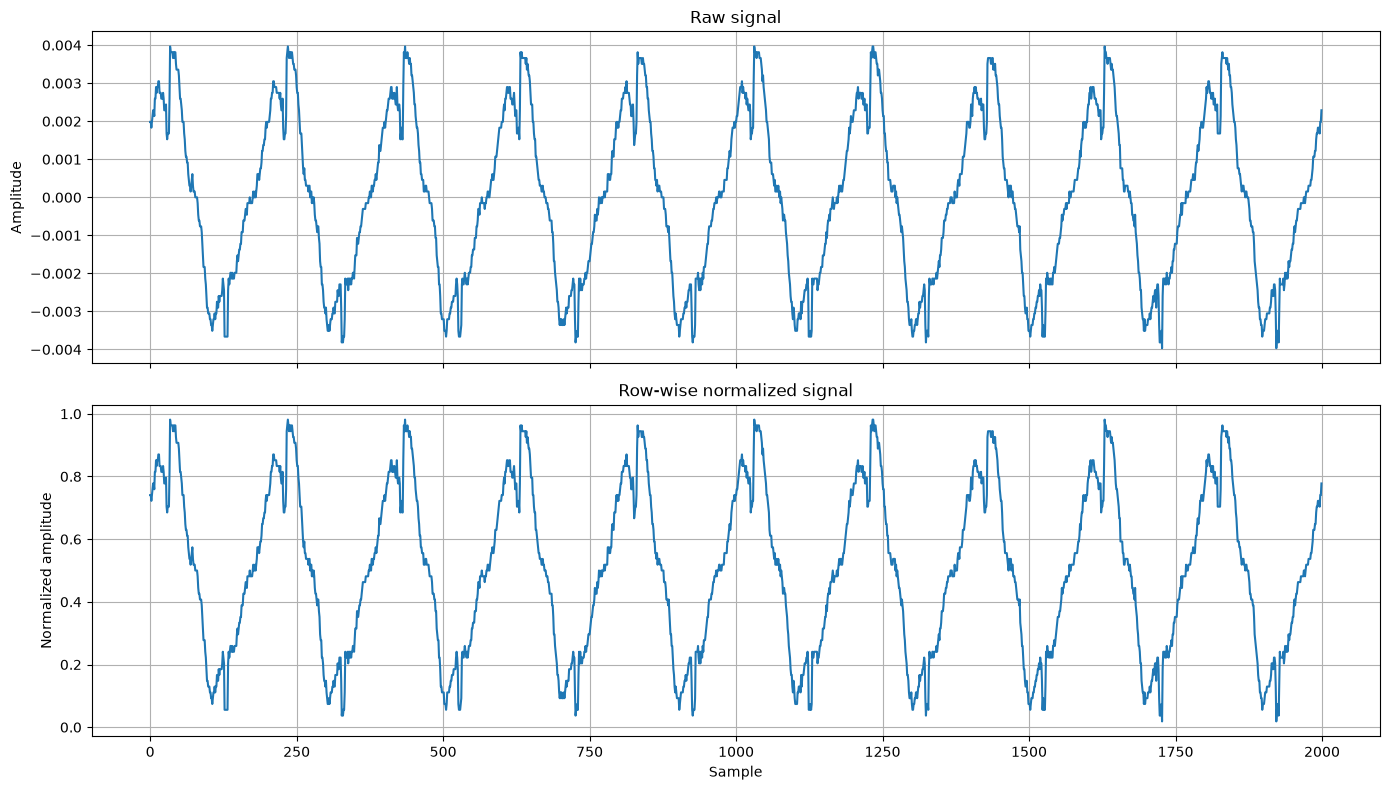

In [11]:
import matplotlib.pyplot as plt

signal_index = 0
n_display = 2000

fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 8),
    sharex=True
)

axes[0].plot(X[signal_index, :n_display])
axes[0].set_title("Raw signal")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

axes[1].plot(X_norm[signal_index, :n_display])
axes[1].set_title("Row-wise normalized signal")
axes[1].set_ylabel("Normalized amplitude")
axes[1].set_xlabel("Sample")
axes[1].grid(True)

plt.tight_layout()
plt.show()

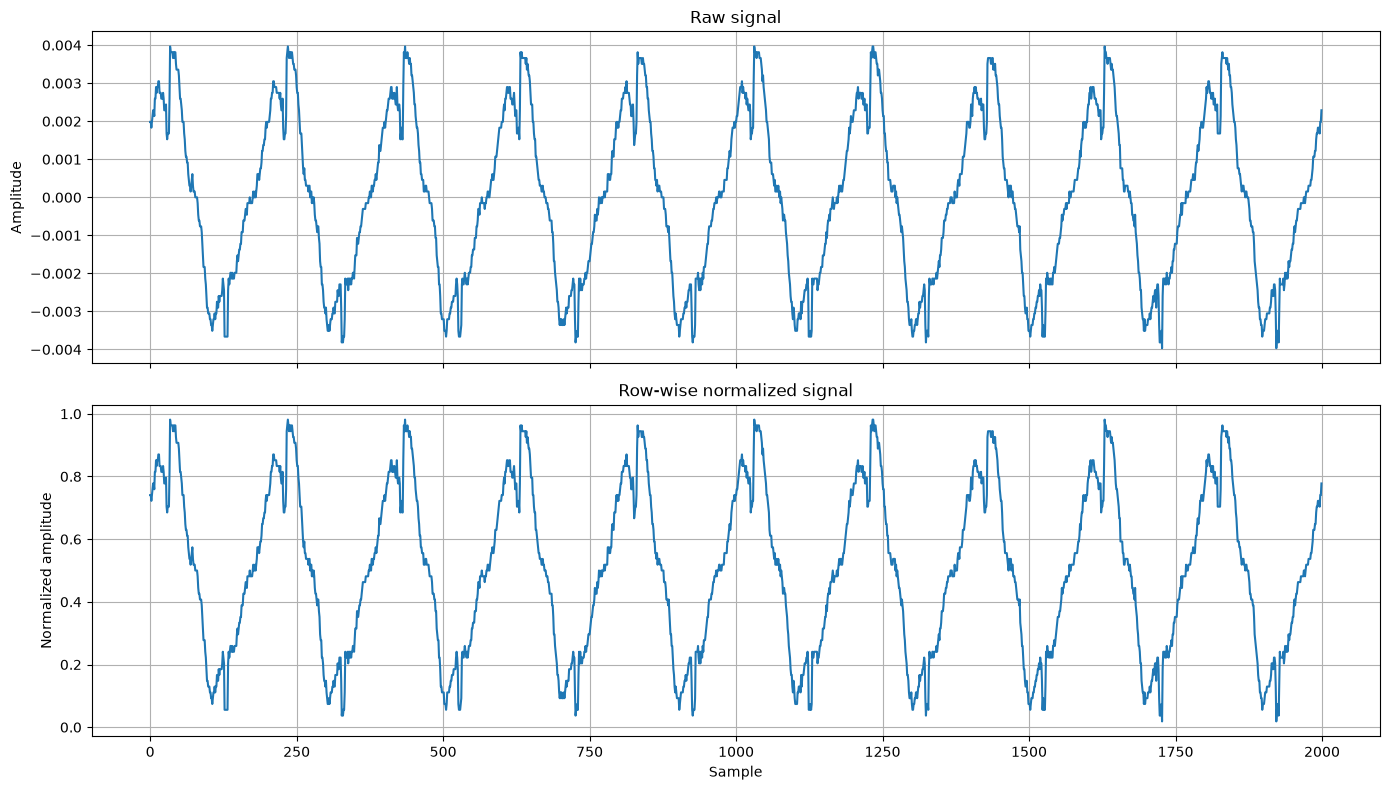

: 

In [ ]:
import matplotlib.pyplot as plt

signal_index = 0
n_display = 2000

fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 8),
    sharex=True
)

axes[0].plot(X[signal_index, :n_display])
axes[0].set_title("Raw signal")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

axes[1].plot(X_norm[signal_index, :n_display])
axes[1].set_title("Row-wise normalized signal")
axes[1].set_ylabel("Normalized amplitude")
axes[1].set_xlabel("Sample")
axes[1].grid(True)

plt.tight_layout()
plt.show()